# Single Artificial Neuron (Logistic Unit) from Scratch

## 1. Overview and Intuition
An **Artificial Neuron** (specifically a logistic unit / single-layer perceptron with a sigmoid activation) is the fundamental building block of deep neural networks. It maps a $D$-dimensional input vector $x$ to a scalar activation $a \in (0, 1)$ representing the predicted probability of the positive class ($y = 1$).

### Mathematical Formulation
1. **Linear Pre-Activation (Dot Product + Bias):**
   $$z = w^T x + b = \sum_{j=1}^D w_j x_j + b$$
2. **Non-Linear Activation (Logistic Sigmoid):**
   $$a = \sigma(z) = \frac{1}{1 + e^{-z}}$$
   Note its derivative: $\sigma'(z) = \sigma(z)(1 - \sigma(z)) = a(1 - a)$.

3. **Binary Cross-Entropy Loss:**
   For a single sample with ground truth $y \in \{0, 1\}$:
   $$\mathcal{L}(y, a) = -\big(y \ln(a) + (1 - y) \ln(1 - a)\big)$$

4. **Backpropagation (Chain Rule):**
   The gradient with respect to the pre-activation $z$ simplifies cleanly:
   $$\frac{\partial \mathcal{L}}{\partial z} = \frac{\partial \mathcal{L}}{\partial a} \cdot \frac{\partial a}{\partial z} = \left(-\frac{y}{a} + \frac{1 - y}{1 - a}\right) \cdot a(1 - a) = a - y$$
   Gradients with respect to weights and bias:
   $$\frac{\partial \mathcal{L}}{\partial w_j} = \frac{\partial \mathcal{L}}{\partial z} \cdot \frac{\partial z}{\partial w_j} = (a - y) x_j$$
   $$\frac{\partial \mathcal{L}}{\partial b} = \frac{\partial \mathcal{L}}{\partial z} \cdot \frac{\partial z}{\partial b} = a - y$$

5. **Parameter Update (Gradient Descent):**
   $$w_j \leftarrow w_j - \alpha \frac{\partial \mathcal{L}}{\partial w_j}, \quad b \leftarrow b - \alpha \frac{\partial \mathcal{L}}{\partial b}$$
   where $\alpha > 0$ is the learning rate.

## 2. Implementation in Pure Python (Zero Dependencies)

In [2]:
import math
import random
from typing import List, Tuple


class Neuron:
    """A single artificial neuron with logistic sigmoid activation."""

    def __init__(self, num_features: int, seed: int = 42) -> None:
        rng = random.Random(seed)
        # Small random weight initialization around 0
        self.w: List[float] = [rng.uniform(-0.1, 0.1) for _ in range(num_features)]
        self.b: float = 0.0

    @staticmethod
    def sigmoid(z: float) -> float:
        """Numerically stable logistic sigmoid function."""
        if z >= 0:
            return 1.0 / (1.0 + math.exp(-z))
        else:
            # Prevents potential overflow when z is large negative
            exp_z = math.exp(z)
            return exp_z / (1.0 + exp_z)

    def forward(self, x: List[float]) -> Tuple[float, float]:
        """Computes forward pass: returns (activation, pre_activation)."""
        z = sum(x_i * w_i for x_i, w_i in zip(x, self.w)) + self.b
        a = self.sigmoid(z)
        return a, z

    def backward(self, x: List[float], y: float, a: float) -> Tuple[List[float], float]:
        """Computes analytical gradients for weights and bias via chain rule."""
        dz = a - y
        dw = [dz * x_i for x_i in x]
        db = dz
        return dw, db

    def train(
        self,
        X: List[List[float]],
        Y: List[float],
        epochs: int = 100,
        learning_rate: float = 0.1,
    ) -> List[float]:
        """Trains the neuron using stochastic gradient descent and returns loss history."""
        loss_history: List[float] = []

        for epoch in range(epochs):
            epoch_loss = 0.0
            for x, y in zip(X, Y):
                a, _ = self.forward(x)

                # Binary Cross-Entropy loss computation with epsilon clipping
                eps = 1e-12
                a_clipped = min(max(a, eps), 1.0 - eps)
                sample_loss = -(y * math.log(a_clipped) + (1.0 - y) * math.log(1.0 - a_clipped))
                epoch_loss += sample_loss

                dw, db = self.backward(x, y, a)

                # Parameter updates
                self.w = [w_i - learning_rate * dw_i for w_i, dw_i in zip(self.w, dw)]
                self.b -= learning_rate * db

            loss_history.append(epoch_loss / len(X))

        return loss_history

    def predict_proba(self, x: List[float]) -> float:
        """Returns predicted probability P(y=1|x)."""
        a, _ = self.forward(x)
        return a

    def predict(self, x: List[float], threshold: float = 0.5) -> int:
        """Returns discrete binary classification label (0 or 1)."""
        return 1 if self.predict_proba(x) >= threshold else 0

## 3. Demonstration on Linearly Separable Binary Dataset

In [3]:
random.seed(42)

# Class 0 centered around (1.5, 1.5)
class_0 = [[random.gauss(1.5, 0.4), random.gauss(1.5, 0.4)] for _ in range(40)]
# Class 1 centered around (4.0, 4.0)
class_1 = [[random.gauss(4.0, 0.4), random.gauss(4.0, 0.4)] for _ in range(40)]

X_train = class_0 + class_1
y_train = [0.0] * 40 + [1.0] * 40

neuron = Neuron(num_features=2, seed=42)
epochs = 80
loss_curve = neuron.train(X_train, y_train, epochs=epochs, learning_rate=0.15)

print(f"Initial Loss: {loss_curve[0]:.4f} -> Final Loss: {loss_curve[-1]:.4f}")
print(f"Trained Weights: [{neuron.w[0]:.4f}, {neuron.w[1]:.4f}] | Bias: {neuron.b:.4f}")

# Test classification accuracy
correct = sum(1 for x, y in zip(X_train, y_train) if neuron.predict(x) == int(y))
print(f"Training Accuracy: {correct / len(X_train) * 100:.1f}%")

Initial Loss: 0.2079 -> Final Loss: 0.0092
Trained Weights: [2.2625, 2.0251] | Bias: -11.1346
Training Accuracy: 100.0%


## 4. Visualizing Loss Convergence & Decision Boundary with Matplotlib

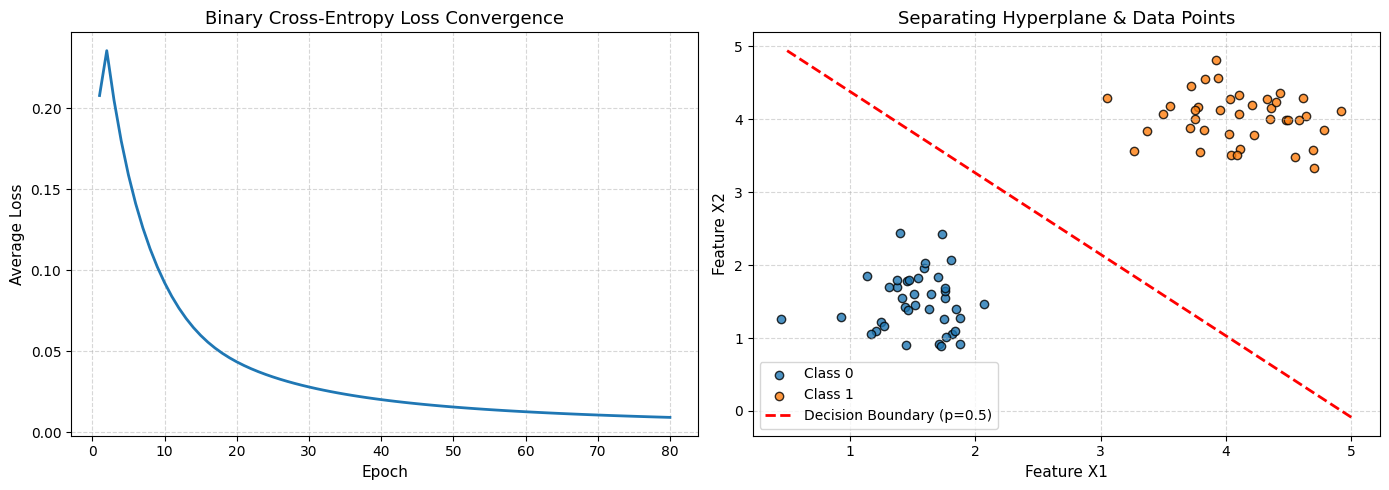

In [4]:
try:
    import matplotlib.pyplot as plt

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Loss Curve
    ax1.plot(range(1, epochs + 1), loss_curve, color="#1f77b4", linewidth=2)
    ax1.set_title("Binary Cross-Entropy Loss Convergence", fontsize=13)
    ax1.set_xlabel("Epoch", fontsize=11)
    ax1.set_ylabel("Average Loss", fontsize=11)
    ax1.grid(True, linestyle="--", alpha=0.5)

    # 2. Decision Boundary: w1*x1 + w2*x2 + b = 0 => x2 = -(w1*x1 + b) / w2
    xs_0 = [p[0] for p in class_0]
    ys_0 = [p[1] for p in class_0]
    xs_1 = [p[0] for p in class_1]
    ys_1 = [p[1] for p in class_1]

    ax2.scatter(xs_0, ys_0, color="#1f77b4", label="Class 0", alpha=0.8, edgecolors="k")
    ax2.scatter(xs_1, ys_1, color="#ff7f0e", label="Class 1", alpha=0.8, edgecolors="k")

    x_boundary = [0.5, 5.0]
    w1, w2 = neuron.w
    b = neuron.b
    y_boundary = [-(w1 * x_val + b) / w2 for x_val in x_boundary]

    ax2.plot(x_boundary, y_boundary, color="red", linestyle="--", linewidth=2, label="Decision Boundary (p=0.5)")
    ax2.set_title("Separating Hyperplane & Data Points", fontsize=13)
    ax2.set_xlabel("Feature X1", fontsize=11)
    ax2.set_ylabel("Feature X2", fontsize=11)
    ax2.legend()
    ax2.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib is not installed in the environment. Skipping visual plot.")